In [1]:
import re
import numpy as np
from pathlib import Path
import pandas as pd
import nibabel as nib
from tqdm.auto import tqdm
import json
from sklearn.model_selection import train_test_split
from concurrent.futures import ProcessPoolExecutor, as_completed
import os
import random
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

In [15]:
# Projekt-Konstanten

PROJECT_DIR = Path("/data_rechenknecht03_2/students/boehmerle")
IMG_DIR = PROJECT_DIR / "img"
SEG_DIR = PROJECT_DIR / "seg"
OUTPUT_DIR = PROJECT_DIR / "outputs"

LABEL_NAMES = {
    0: "background",
    1: "bone_cortex",
    2: "femur_head",
    3: "ilium",
    4: "chondro_osseous_border",
}
LABEL_COLORS = [            # Colors taken from CD UzL
    (0.0, 0.0, 0.0, 0.0),   # Background: transparent
    "#004b5a",              # bone_cortex
    "#e42032",              # femur_head
    "#fabb00",              # ilium
    "#6ea5ce",              # chondro_osseous_border
]
LABELS = LABEL_NAMES.keys()
LABEL_COUNT = len(LABELS)

SEED = 42
MAX_WORKERS = min(8, os.cpu_count() or 1)

EXAMPLE_SWEEP = 0

In [16]:
# Helper-Funktionen

# Infos aus dem Dateinamen auslesen
def parse_filename(path: Path) -> dict:
    name = path.name
    match = re.match(
        r"^(?P<case_id>.+?)_sweep(?P<sweep>\d+)_(?P<side>rechts|links)_1x_p_[ad]_(?P<kind>rec|seg)\.nii\.gz$",
        name,
    )
    if match is None:
        raise ValueError(f"Unerwartetes Dateinamensschema: {name}")
    return match.groupdict()

# Nicht-Null-Voxel normalisieren. Null-Voxel (Hintergrund) bleiben bei 0.
def normalize_nonzero_zscore(image: np.ndarray) -> np.ndarray:
    image = image.astype(np.float32, copy=True)
    nonzero = image > 0

    if not np.any(nonzero):
        raise ValueError("Bild enthält keine Nicht-Null-Voxel.")

    mean = image[nonzero].mean()
    std = image[nonzero].std()

    if std == 0:
        raise ValueError("Nicht-Null-Voxel haben keine Intensitätsstreuung.")

    image[nonzero] = (image[nonzero] - mean) / std
    image[~nonzero] = 0.0
    return image

label_cmap = ListedColormap(LABEL_COLORS)
label_norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), label_cmap.N)

# Center einer Bounding-Box auf einer Achse berechnen
def foreground_center(seg: np.ndarray, axis: int) -> int:
    coords = np.where(seg > 0)[axis]
    if coords.size == 0:
        return seg.shape[axis] // 2
    return int((coords.min() + coords.max()) // 2)

# 2D-Slice extrahieren und rotieren
def get_slice(volume: np.ndarray, axis: int, index: int) -> np.ndarray:
    if axis == 0:
        return np.rot90(volume[index, :, :])
    if axis == 1:
        return np.rot90(volume[:, index, :])
    return np.rot90(volume[:, :, index])

# Sweep-Overlay anzeigen
def show_sweep_overlay(row: pd.Series) -> None:
    image = np.asanyarray(nib.load(row.image_path).dataobj)
    segmentation = np.asanyarray(nib.load(row.label_path).dataobj).astype(np.uint8)

    views = [
        ("Achse 0", 0),
        ("Achse 1", 1),
        ("Achse 2", 2),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(
        f"Fall {row.case_id} | {row.sweep_id} | {row.side}",
        fontsize=14,
        fontweight="bold",
    )

    for ax, (view_name, axis) in zip(axes, views):
        slice_index = foreground_center(segmentation, axis)
        image_slice = get_slice(image, axis, slice_index)
        seg_slice = get_slice(segmentation, axis, slice_index)

        masked_seg = np.ma.masked_where(seg_slice == 0, seg_slice)

        ax.imshow(image_slice, cmap="gray", interpolation="nearest")
        ax.imshow(
            masked_seg,
            cmap=label_cmap,
            norm=label_norm,
            alpha=0.65,
            interpolation="nearest",
        )
        ax.set_title(f"{view_name}, Slice {slice_index}")
        ax.axis("off")

    handles = [
        plt.Line2D([0], [0], color=LABEL_COLORS[i], lw=5, label=LABEL_NAMES[i])
        for i in range(1, 5)
    ]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
    plt.tight_layout(rect=[0, 0.08, 1, 0.93])
    plt.show()

In [4]:
# Projekt aufsetzen

# Output-Ordner anlegen
OUTPUT_DIR.mkdir(exist_ok=True)
# Daten-Ordner müssen existieren
assert IMG_DIR.is_dir(), f"Nicht gefunden: {IMG_DIR}"
assert SEG_DIR.is_dir(), f"Nicht gefunden: {SEG_DIR}"

In [17]:
# Manifest aus bestehenden Daten generieren
image_paths = sorted(IMG_DIR.glob("*rec.nii.gz"))
rows = []

for image_path in image_paths:
    label_name = image_path.name.replace("rec.nii.gz", "seg.nii.gz")
    label_path = SEG_DIR / label_name
    info = parse_filename(image_path)

    rows.append({
        "case_id": info["case_id"],
        "sweep_id": f"sweep{info['sweep']}",
        "side": info["side"],
        "image_path": str(image_path),
        "label_path": str(label_path),
        "pair_status": "ok" if label_path.is_file() else "missing_label",
    })

manifest = pd.DataFrame(rows)

manifest_path = OUTPUT_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False)

display(manifest.head())
print(f"Bilddateien: {len(manifest)}")
print(f"Vollständige Paare: {(manifest['pair_status'] == 'ok').sum()}")
print(f"Fälle: {manifest['case_id'].nunique()}")
print(f"Fehlende Labels: {(manifest['pair_status'] != 'ok').sum()}")
print(f"Gespeichert: {manifest_path}")

,case_id,sweep_id,side,image_path,label_path,pair_status
0,0EXN9,sweep01,rechts,/data_rechenknecht03_2/students/boehmerle/img/...,/data_rechenknecht03_2/students/boehmerle/seg/...,ok
1,0EXN9,sweep02,rechts,/data_rechenknecht03_2/students/boehmerle/img/...,/data_rechenknecht03_2/students/boehmerle/seg/...,ok
2,0EXN9,sweep04,links,/data_rechenknecht03_2/students/boehmerle/img/...,/data_rechenknecht03_2/students/boehmerle/seg/...,ok
3,0EXN9,sweep05,links,/data_rechenknecht03_2/students/boehmerle/img/...,/data_rechenknecht03_2/students/boehmerle/seg/...,ok
4,0IRBPU,sweep01,rechts,/data_rechenknecht03_2/students/boehmerle/img/...,/data_rechenknecht03_2/students/boehmerle/seg/...,ok


Bilddateien: 190
Vollständige Paare: 190
Fälle: 50
Fehlende Labels: 0
Gespeichert: /data_rechenknecht03_2/students/boehmerle/outputs/manifest.csv


In [ ]:
# Qualitäts-Check: Stimmen Shape, Spacing, und Affine überein? Haben alle Daten maximal die 5 labels?

pass

records = []

for row in tqdm(manifest.query("pair_status == 'ok'").itertuples(), total=len(manifest)):
    img_nii = nib.load(row.image_path)
    seg_nii = nib.load(row.label_path)

    img_shape = tuple(img_nii.shape)
    seg_shape = tuple(seg_nii.shape)
    img_spacing = tuple(np.round(img_nii.header.get_zooms()[:3], 6))
    seg_spacing = tuple(np.round(seg_nii.header.get_zooms()[:3], 6))

    seg_data = np.asanyarray(seg_nii.dataobj)
    label_values = sorted(np.unique(seg_data).astype(int).tolist())
    
    records.append({
        "case_id": row.case_id,
        "sweep_id": row.sweep_id,
        "side": row.side,
        "image_path": row.image_path,
        "label_path": row.label_path,
        "image_shape": str(img_shape),
        "label_shape": str(seg_shape),
        "image_spacing_mm": str(img_spacing),
        "label_spacing_mm": str(seg_spacing),
        "shape_match": img_shape == seg_shape,
        "spacing_match": np.allclose(img_spacing, seg_spacing, atol=1e-6),
        "affine_match": np.allclose(img_nii.affine, seg_nii.affine, atol=1e-5),
        "label_values": str(label_values),
        "valid_label_values": set(label_values).issubset(LABELS),
    })

qc = pd.DataFrame(records)
qc_path = OUTPUT_DIR / "nifti_qc.csv"
qc.to_csv(qc_path, index=False)

checks = ["shape_match", "spacing_match", "affine_match", "valid_label_values"]
display(qc[~qc[checks].all(axis=1)])

for check in checks:
    print(f"{check}: {qc[check].sum()} / {len(qc)} unauffällig")

print("\nTatsächlich vorkommende Labelwerte:")
print(sorted(set().union(*qc["label_values"].map(lambda x: set(eval(x))))))
print(f"\nGespeichert: {qc_path}")

  0%|          | 0/190 [00:00<?, ?it/s]

In [7]:
# Aufteilen in Training, Validation und Test-Datensätze
case_ids = sorted(manifest.loc[
    manifest["pair_status"] == "ok", "case_id"
].unique())

train_cases, temp_cases = train_test_split(
    case_ids,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
)

val_cases, test_cases = train_test_split(
    temp_cases,
    test_size=8 / len(temp_cases),
    random_state=SEED,
    shuffle=True,
)

case_to_split = {
    **{case_id: "training" for case_id in train_cases},
    **{case_id: "validation" for case_id in val_cases},
    **{case_id: "test" for case_id in test_cases},
}

manifest["split"] = manifest["case_id"].map(case_to_split)

assert manifest["split"].notna().all()
assert manifest.groupby("case_id")["split"].nunique().max() == 1

split_summary = (
    manifest.groupby("split")
    .agg(cases=("case_id", "nunique"), sweeps=("case_id", "size"))
    .reindex(["training", "validation", "test"])
)

display(split_summary)

split_cases = pd.DataFrame(
    [{"case_id": case_id, "split": split_name}
     for case_id, split_name in case_to_split.items()]
).sort_values(["split", "case_id"])

split_cases.to_csv(OUTPUT_DIR / f"case_split_seed{SEED}.csv", index=False)
manifest.to_csv(OUTPUT_DIR / "manifest_with_split.csv", index=False)

,cases,sweeps
split,,
training,35,132
validation,7,26
test,8,32


In [8]:
# Klassenverteilung ermitteln: Sind manche Labels bedeutend mehr vorhanden als andere?

def count_labels(label_path: str, num_classes: int) -> np.ndarray:
    seg_nii = nib.load(label_path)
    seg_data = np.asanyarray(seg_nii.dataobj).astype(np.int16)
    counts = np.bincount(seg_data.ravel(), minlength=num_classes)
    return counts[:num_classes]

rows = manifest.query("pair_status == 'ok'").reset_index(drop=True)

label_counts = {split: np.zeros(LABEL_COUNT, dtype=np.int64)
                for split in ["training", "validation", "test"]}

with ProcessPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = {
        executor.submit(count_labels, row.label_path, LABEL_COUNT): row.split
        for row in rows.itertuples()
    }
    for future in tqdm(as_completed(futures), total=len(futures)):
        split_name = futures[future]
        label_counts[split_name] += future.result()

label_distribution = pd.DataFrame(
    label_counts,
    index=[LABEL_NAMES[i] for i in range(LABEL_COUNT)]
).T

foreground_voxels = label_distribution.drop(columns="background")
label_percentages = (
    foreground_voxels
    .div(foreground_voxels.sum(axis=1), axis=0)
    .mul(100)
    .round(3)
)

display(label_distribution)
display(foreground_voxels)
display(label_percentages)

label_distribution.to_csv(OUTPUT_DIR / "label_voxel_counts_by_split.csv")
label_percentages.to_csv(OUTPUT_DIR / "label_voxel_percentages_by_split.csv")

  0%|          | 0/190 [00:00<?, ?it/s]

,background,bone_cortex,femur_head,ilium,chondro_osseous_border
training,8293389297,3480653,16284941,6515452,306533
validation,1708895336,801926,3676075,1627672,62181
test,1953771484,806651,3942581,1528670,74072


,bone_cortex,femur_head,ilium,chondro_osseous_border
training,3480653,16284941,6515452,306533
validation,801926,3676075,1627672,62181
test,806651,3942581,1528670,74072


,bone_cortex,femur_head,ilium,chondro_osseous_border
training,13.091,61.250,24.506,1.153
validation,13.002,59.601,26.390,1.008
test,12.699,62.069,24.066,1.166


In [12]:
# Ein Bild über die Bildintensitäten bekommen

rng = random.Random(SEED)
sample_rows = rng.sample(
    list(manifest.query("pair_status == 'ok'").itertuples()),
    k=10,
)

intensity_records = []
nonzero_stats = []

for row in sample_rows:
    img_nii = nib.load(row.image_path)
    img_data = np.asanyarray(img_nii.dataobj)

    intensity_records.append({
        "case_id": row.case_id,
        "sweep_id": row.sweep_id,
        "dtype": str(img_data.dtype),
        "min": float(img_data.min()),
        "max": float(img_data.max()),
        "mean": float(img_data.mean()),
        "p01": float(np.percentile(img_data, 1)),
        "p99": float(np.percentile(img_data, 99)),
    })

    nonzero = img_data[img_data > 0]

    nonzero_stats.append({
        "case_id": row.case_id,
        "sweep_id": row.sweep_id,
        "nonzero_fraction_pct": round(100 * nonzero.size / img_data.size, 3),
        "nonzero_p01": float(np.percentile(nonzero, 1)),
        "nonzero_p50": float(np.percentile(nonzero, 50)),
        "nonzero_p99": float(np.percentile(nonzero, 99)),
        "nonzero_max": float(nonzero.max()),
    })

intensity_df = pd.DataFrame(intensity_records)
display(intensity_df)
nonzero_stats_df = pd.DataFrame(nonzero_stats)
display(nonzero_stats_df)

,case_id,sweep_id,dtype,min,max,mean,p01,p99
0,UWMKHQ,sweep05,uint8,0.0,252.0,7.959339,0.0,106.0
1,71JZK7,sweep01,uint8,0.0,243.0,4.467692,0.0,90.0
2,0IRBPU,sweep04,uint8,0.0,248.0,5.143180,0.0,96.0
3,ZOX664,sweep05,uint8,0.0,251.0,11.375535,0.0,116.0
4,CB0ZUM,sweep01,uint8,0.0,246.0,4.726239,0.0,93.0
5,BO96VQ,sweep01,uint8,0.0,250.0,3.113029,0.0,89.0
6,B8B9AF,sweep02,uint8,0.0,252.0,9.419856,0.0,119.0
7,7S78PO,sweep05,uint8,0.0,247.0,9.516583,0.0,115.0
8,ZOX664,sweep04,uint8,0.0,236.0,5.881141,0.0,101.0
9,4YU2OP,sweep04,uint8,0.0,250.0,5.854591,0.0,99.0


,case_id,sweep_id,nonzero_fraction_pct,nonzero_p01,nonzero_p50,nonzero_p99,nonzero_max
0,UWMKHQ,sweep05,18.439,1.0,33.0,151.0,252.0
1,71JZK7,sweep01,8.381,5.0,44.0,146.0,243.0
2,0IRBPU,sweep04,10.759,1.0,36.0,147.0,248.0
3,ZOX664,sweep05,26.044,1.0,32.0,145.0,251.0
4,CB0ZUM,sweep01,10.417,2.0,33.0,146.0,246.0
5,BO96VQ,sweep01,5.798,5.0,41.0,152.0,250.0
6,B8B9AF,sweep02,20.887,1.0,33.0,156.0,252.0
7,7S78PO,sweep05,18.714,1.0,40.0,154.0,247.0
8,ZOX664,sweep04,12.607,4.0,34.0,140.0,236.0
9,4YU2OP,sweep04,11.890,1.0,40.0,144.0,250.0


Fester Referenzsweep:


,case_id,sweep_id,side,image_path,label_path,pair_status
0,0EXN9,sweep04,links,/data_rechenknecht03_2/students/boehmerle/img/...,/data_rechenknecht03_2/students/boehmerle/seg/...,ok


Zufällig ausgewählter Sweep:


,case_id,sweep_id,side,image_path,label_path,pair_status
185,Y9N6HY,sweep02,rechts,/data_rechenknecht03_2/students/boehmerle/img/...,/data_rechenknecht03_2/students/boehmerle/seg/...,ok


/usr/lib/python3/dist-packages/matplotlib/colors.py:235: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  c = np.array(c)


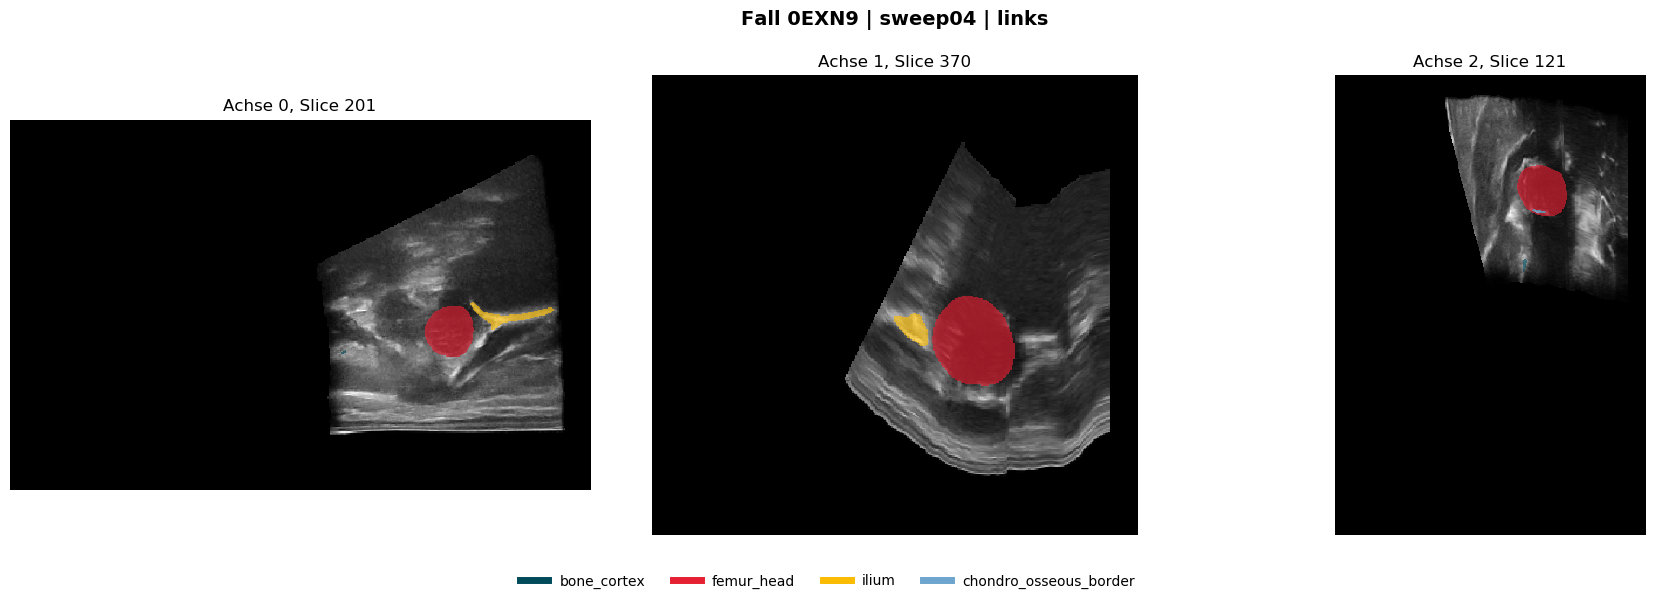

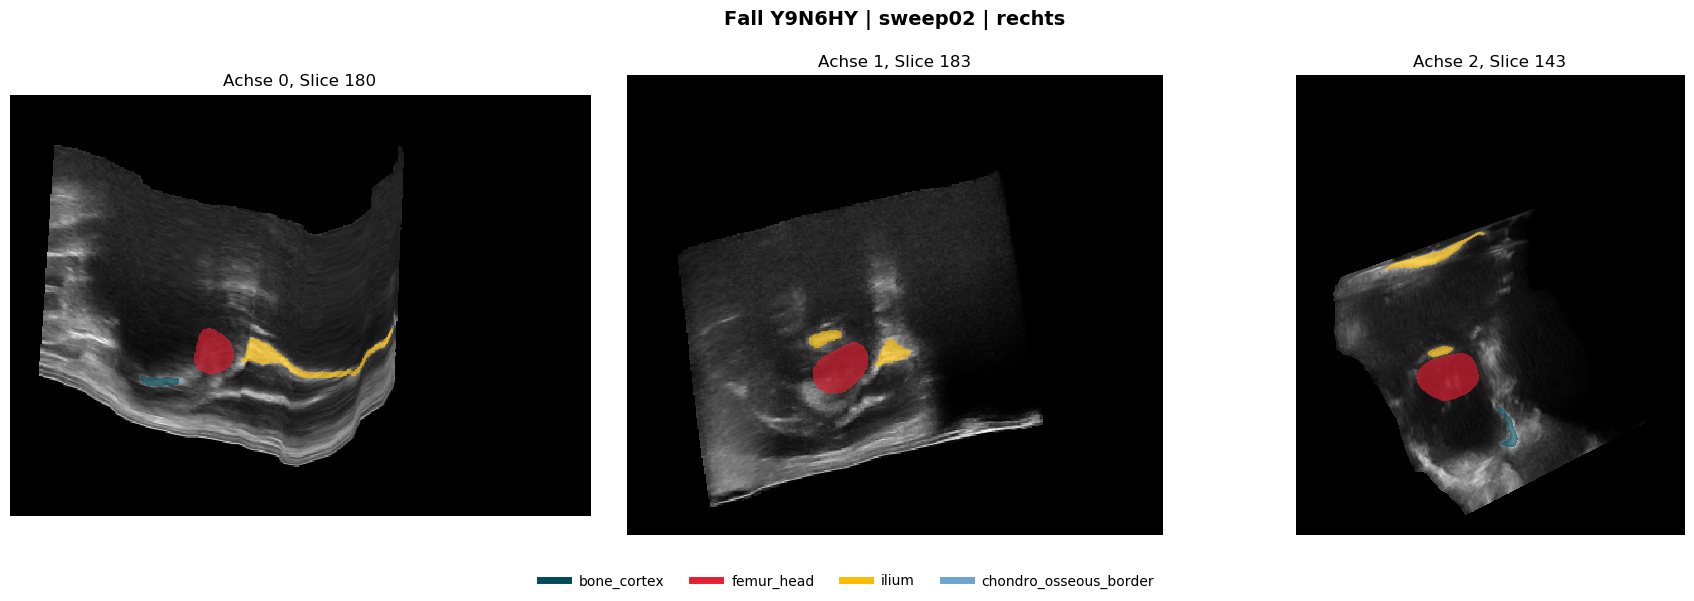

In [18]:
# Visualisierung eines Referenz-Sweeps und eines zufälligen Sweeps

valid_manifest = (
    manifest.query("pair_status == 'ok'")
    .sort_values(["case_id", "side", "sweep_id"])
    .reset_index(drop=True)
)

fixed_sweep = valid_manifest.iloc[EXAMPLE_SWEEP]

random_sweep = (
    valid_manifest
    .drop(index=EXAMPLE_SWEEP)
    .sample(n=1, random_state=SEED)
    .iloc[0]
)

print("Fester Referenzsweep:")
display(pd.DataFrame([fixed_sweep]))

print("Zufällig ausgewählter Sweep:")
display(pd.DataFrame([random_sweep]))

show_sweep_overlay(fixed_sweep)
show_sweep_overlay(random_sweep)